# Análise exploratória dos embargos do ICMBio

Este notebook analisa os embargos presentes na publicação mais recente do ICMBio. Os dados já passaram pelas camadas RAW e STG e foram organizados no modelo dimensional do Data Warehouse.

## Objetivos

- Avaliar a qualidade dos dados;
- construir os principais indicadores de negócio;
- analisar a distribuição geográfica e temporal;
- identificar valores de área muito acima do padrão;
- selecionar informações relevantes para o dashboard no Power BI.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from icmbio_pipeline.banco import conectar
from icmbio_pipeline.configuracao import carregar_configuracao

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Extração dos dados do Data Warehouse

A view `dw.vw_embargo_atual` contém somente os embargos presentes na publicação mais recente.

Para enriquecer a análise, a view será relacionada com as dimensões de tempo, localidade, unidade de conservação, infração e origem.

In [2]:
consulta = """
    SELECT
        f.embargo_id_fonte,
        f.numero_embargo,
        f.numero_auto_infracao,
        f.numero_processo,
        f.quantidade_embargo,
        f.area_original,
        f.area_ha,
        f.area_valida,
        t.data_completa AS data_embargo,
        t.ano,
        t.mes,
        t.nome_mes,
        l.municipio,
        l.uf,
        u.codigo_cnuc,
        u.nome_unidade,
        i.tipo_infracao,
        i.artigo_1,
        i.artigo_2,
        o.origem,
        o.serie
    FROM dw.vw_embargo_atual AS f
    JOIN dw.dim_tempo AS t
        ON t.tempo_sk = f.tempo_sk
    JOIN dw.dim_localidade AS l
        ON l.localidade_sk = f.localidade_sk
    JOIN dw.dim_unidade_conservacao AS u
        ON u.unidade_sk = f.unidade_sk
    JOIN dw.dim_infracao AS i
        ON i.infracao_sk = f.infracao_sk
    JOIN dw.dim_origem AS o
        ON o.origem_sk = f.origem_sk
    ORDER BY f.embargo_id_fonte
"""

configuracao = carregar_configuracao()
conexao = conectar(configuracao)
cursor = conexao.cursor()

try:
    cursor.execute(consulta)
    colunas = [coluna[0] for coluna in cursor.description]
    dados = pd.DataFrame(cursor.fetchall(), columns=colunas)
finally:
    cursor.close()
    conexao.close()

dados["data_embargo"] = pd.to_datetime(dados["data_embargo"])
dados["area_ha"] = pd.to_numeric(dados["area_ha"], errors="coerce")

print(f"Quantidade de linhas: {len(dados):,}")
print(f"Quantidade de colunas: {len(dados.columns)}")
dados.head()

Quantidade de linhas: 14,781
Quantidade de colunas: 21


,embargo_id_fonte,numero_embargo,numero_auto_infracao,numero_processo,quantidade_embargo,area_original,area_ha,area_valida,data_embargo,ano,mes,nome_mes,municipio,uf,codigo_cnuc,nome_unidade,tipo_infracao,artigo_1,artigo_2,origem,serie
0,1,000005,000005-A,02070.001647/2010-31,1,0,0.00,True,2009-09-20,"2,009.00",9.00,Setembro,PORTO VELHO,RO,0000.00.0116,FLONA DO BOM FUTURO,DAS INFRAÇÕES RELATIVAS À POLUIÇÃO E OUTRAS IN...,66,93,PAPEL,A
1,2,000008,000008-A,02070.001646/2010-96,1,0,0.00,True,2009-09-20,"2,009.00",9.00,Setembro,PORTO VELHO,RO,0000.00.0116,FLONA DO BOM FUTURO,DAS INFRAÇÕES RELATIVAS À POLUIÇÃO E OUTRAS IN...,66,93,PAPEL,A
2,3,000010,000010-A,02070.002846/2009-22,1,Não informada,NaN,False,2009-10-08,"2,009.00",10.00,Outubro,MAMBAÍ,GO,0000.00.0028,APA DAS NASCENTES DO RIO VERMELHO,DAS INFRAÇÕES RELATIVAS À POLUIÇÃO E OUTRAS IN...,66,93,PAPEL,A
3,4,000011,000011-A,02070.002854/2009-79,1,"0,4416 ha",0.44,True,2009-10-08,"2,009.00",10.00,Outubro,MAMBAÍ,GO,0000.00.0028,APA DAS NASCENTES DO RIO VERMELHO,DAS INFRAÇÕES CONTRA A FLORA,43,93,PAPEL,A
4,5,000012,000012-A,02070.002847/2009-77,1,100 m,NaN,False,2009-10-08,"2,009.00",10.00,Outubro,MAMBAÍ,GO,0000.00.0028,APA DAS NASCENTES DO RIO VERMELHO,DAS INFRAÇÕES RELATIVAS À POLUIÇÃO E OUTRAS IN...,66,93,PAPEL,A


## 2. Estrutura e qualidade dos dados

Nesta etapa serão verificadas:

- a quantidade de linhas e colunas;
- os tipos das colunas;
- os valores ausentes;
- a quantidade de valores únicos;
- a existência de identificadores duplicados;
- o período coberto pelos dados.

In [3]:
resumo_qualidade = pd.DataFrame({
    "tipo": dados.dtypes.astype(str),
    "ausentes": dados.isna().sum(),
    "percentual_ausente": dados.isna().mean().mul(100).round(2),
    "valores_unicos": dados.nunique(dropna=True),
})

resumo_qualidade

,tipo,ausentes,percentual_ausente,valores_unicos
embargo_id_fonte,int64,0,0.00,14781
numero_embargo,object,0,0.00,13330
numero_auto_infracao,object,2164,14.64,11446
numero_processo,object,3406,23.04,10352
quantidade_embargo,int64,0,0.00,1
area_original,object,3044,20.59,8566
area_ha,float64,3724,25.19,7015
area_valida,bool,0,0.00,2
data_embargo,datetime64[ns],5,0.03,4016
ano,float64,5,0.03,18


In [4]:
duplicados = dados["embargo_id_fonte"].duplicated().sum()
print(f"Identificadores duplicados: {duplicados}")
print(f"Menor data: {dados['data_embargo'].min()}")
print(f"Maior data: {dados['data_embargo'].max()}")


Identificadores duplicados: 0
Menor data: 2009-05-17 00:00:00
Maior data: 2026-10-01 00:00:00


## 3. Indicadores gerais

Os indicadores gerais apresentam uma visão resumida da base atual:

- quantidade total de embargos;
- estados e municípios representados;
- unidades de conservação;
- registros com área válida;
- percentual de registros com área válida;
- área total e área mediana.

In [5]:
areas_validas = dados.loc[dados["area_valida"], "area_ha"]

indicadores = pd.Series({
    "Quantidade de embargos": len(dados),
    "Estados representados": dados.loc[dados["uf"] != "NAO_INFORMADA", "uf"].nunique(),
    "Municípios representados": dados["municipio"].nunique(),
    "Unidades de conservação": dados["codigo_cnuc"].nunique(),
    "Registros com área válida": int(dados["area_valida"].sum()),
    "Percentual com área válida": dados["area_valida"].mean() * 100,
    "Área total válida em hectares": areas_validas.sum(),
    "Área mediana em hectares": areas_validas.median(),
})

indicadores.to_frame("valor")

,valor
Quantidade de embargos,"14,781.00"
Estados representados,27.00
Municípios representados,642.00
Unidades de conservação,281.00
Registros com área válida,"11,057.00"
Percentual com área válida,74.81
Área total válida em hectares,"3,310,043.69"
Área mediana em hectares,4.05


## 4. Distribuição e possíveis outliers de área

Nesta etapa será analisada a distribuição da área embargada em hectares.

Valores muito acima do padrão serão identificados pelo método do intervalo interquartil, conhecido como IQR.

Um valor extremo não representa necessariamente um erro. Por isso, os possíveis outliers serão investigados, mas não serão removidos automaticamente.

In [6]:
areas_validas.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame("area_ha")

,area_ha
count,"11,057.00"
mean,299.36
std,"4,824.90"
min,0.00
25%,0.48
50%,4.05
75%,21.00
90%,98.56
95%,273.45
99%,"2,673.15"


In [7]:
q1 = areas_validas.quantile(0.25)
q3 = areas_validas.quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

possiveis_outliers = dados.loc[
    dados["area_valida"] & (dados["area_ha"] > limite_superior),
    ["embargo_id_fonte", "area_original", "area_ha", "municipio", "uf", "nome_unidade"],
].sort_values("area_ha", ascending=False)

print(f"Limite superior pelo método IQR: {limite_superior:,.2f} ha")
print(f"Quantidade de possíveis outliers: {len(possiveis_outliers):,}")
possiveis_outliers.head(20)

Limite superior pelo método IQR: 51.78 ha
Quantidade de possíveis outliers: 1,670


,embargo_id_fonte,area_original,area_ha,municipio,uf,nome_unidade
13040,14557,309509 ha,"309,509.00",LÁBREA,AM,FLONA DO IQUIRI
11671,13188,184583 ha,"184,583.00",ALTAMIRA,PA,ESEC DA TERRA DO MEIO
10146,11663,151671 ha,"151,671.00",ALTAMIRA,PA,ESEC DA TERRA DO MEIO
14363,15880,"108395,8010 ha","108,395.80",LAGOA DA CONFUSÃO,TO,PARNA DO ARAGUAIA
14229,15746,98562 ha,"98,562.00",SÃO FÉLIX DO XINGU,PA,PARNA DA SERRA DO PARDO
10306,11823,"86080,5800 ha","86,080.58",BRAGANÇA,PA,RESEX MARINHA DE CAETÉ-TAPERAÇU
10308,11825,"86080,5800 ha","86,080.58",BRAGANÇA,PA,RESEX MARINHA DE CAETÉ-TAPERAÇU
10305,11822,"86080,5800 ha","86,080.58",BRAGANÇA,PA,RESEX MARINHA DE CAETÉ-TAPERAÇU
10307,11824,"86080,5800 ha","86,080.58",BRAGANÇA,PA,RESEX MARINHA DE CAETÉ-TAPERAÇU
10309,11826,"86080,5800 ha","86,080.58",BRAGANÇA,PA,RESEX MARINHA DE CAETÉ-TAPERAÇU


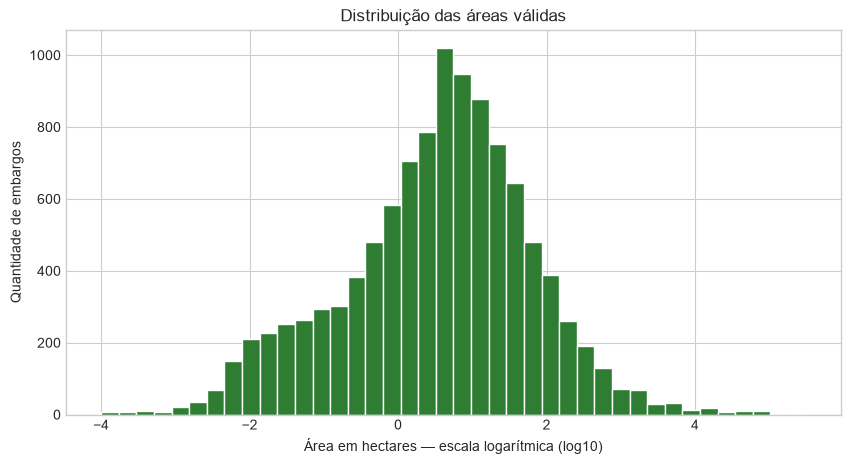

In [8]:
areas_positivas = areas_validas[areas_validas > 0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log10(areas_positivas), bins=40, color="#2E7D32", edgecolor="white")
ax.set_title("Distribuição das áreas válidas")
ax.set_xlabel("Área em hectares — escala logarítmica (log10)")
ax.set_ylabel("Quantidade de embargos")
plt.show()

## 5. Distribuição geográfica

A distribuição geográfica permite identificar os estados com maior quantidade de embargos e maior área total embargada.

A análise será feita inicialmente por unidade federativa. Posteriormente, o Power BI permitirá aplicar filtros por município e unidade de conservação.


In [9]:
por_uf = (
    dados.groupby("uf", as_index=False)
    .agg(
        quantidade_embargos=("embargo_id_fonte", "count"),
        area_total_ha=("area_ha", "sum"),
    )
    .sort_values("quantidade_embargos", ascending=False)
)

por_uf

,uf,quantidade_embargos,area_total_ha
14,PA,4149,"1,548,531.35"
0,AC,1264,"13,163.11"
24,SC,1005,658.94
4,BA,953,"53,286.40"
10,MG,855,"15,694.58"
19,RJ,846,865.46
6,DF,742,"3,565.79"
21,RO,695,"117,748.93"
5,CE,510,"14,286.23"
18,PR,450,"88,944.79"


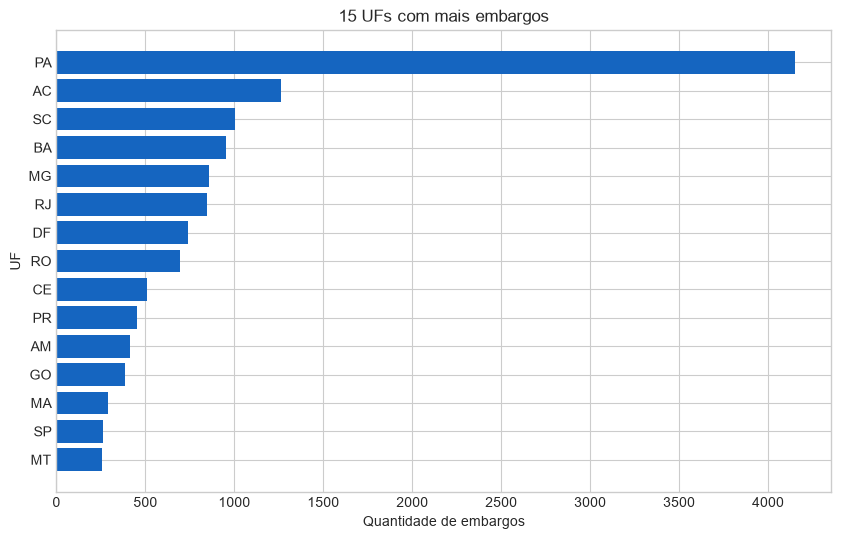

In [10]:
grafico_uf = por_uf.head(15).sort_values("quantidade_embargos")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(grafico_uf["uf"], grafico_uf["quantidade_embargos"], color="#1565C0")
ax.set_title("15 UFs com mais embargos")
ax.set_xlabel("Quantidade de embargos")
ax.set_ylabel("UF")
plt.show()

## 6. Evolução temporal

A análise temporal mostra como a quantidade de embargos registrados varia ao longo dos anos.

É importante observar que o ano representa a data do embargo e não necessariamente o ano em que o registro foi inserido no Data Warehouse.

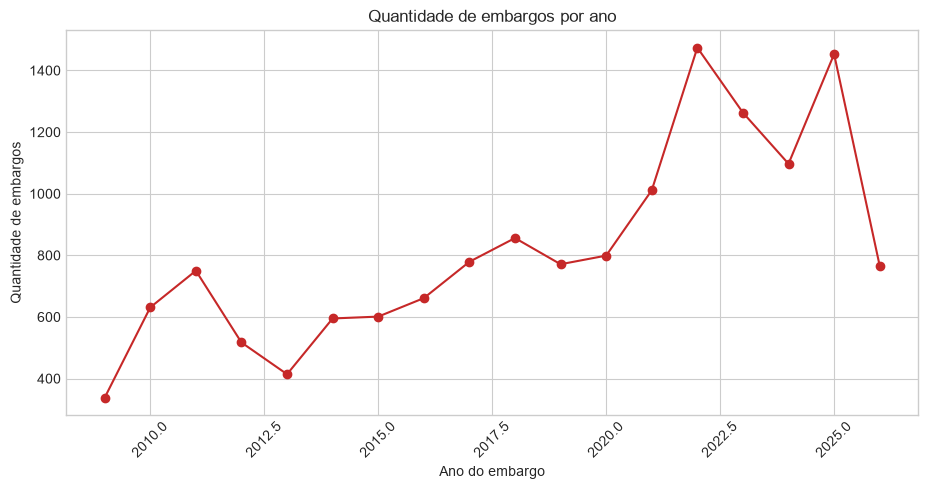

,ano,quantidade_embargos
3,"2,012.00",517
4,"2,013.00",414
5,"2,014.00",595
6,"2,015.00",601
7,"2,016.00",661
8,"2,017.00",779
9,"2,018.00",856
10,"2,019.00",771
11,"2,020.00",799
12,"2,021.00",1011


In [11]:
por_ano = (
    dados.dropna(subset=["ano"])
    .groupby("ano", as_index=False)
    .agg(quantidade_embargos=("embargo_id_fonte", "count"))
    .sort_values("ano")
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(por_ano["ano"], por_ano["quantidade_embargos"], marker="o", color="#C62828")
ax.set_title("Quantidade de embargos por ano")
ax.set_xlabel("Ano do embargo")
ax.set_ylabel("Quantidade de embargos")
plt.xticks(rotation=45)
plt.show()

por_ano.tail(15)

## 7. Unidades de conservação e tipos de infração

Nesta etapa serão identificadas:

- as unidades de conservação com maior quantidade de embargos;
- os tipos de infração mais frequentes;
- a concentração dos registros entre as diferentes categorias.

Esses rankings poderão ser utilizados como visualizações e filtros no dashboard.

In [12]:
top_unidades = (
    dados.groupby(["codigo_cnuc", "nome_unidade"], as_index=False)
    .agg(quantidade_embargos=("embargo_id_fonte", "count"))
    .sort_values("quantidade_embargos", ascending=False)
    .head(15)
)

top_unidades

,codigo_cnuc,nome_unidade,quantidade_embargos
209,0000.00.0266,FLONA DO JAMANXIM,941
173,0000.00.0222,RESEX CHICO MENDES,792
31,0000.00.0047,ESEC DA TERRA DO MEIO,381
107,0000.00.0142,PARNA DA SERRA DA BOCAINA,374
211,0000.00.0268,APA DO TAPAJÓS,358
170,0000.00.0216,REBIO NASCENTES DA SERRA DO CACHIMBO,309
5,0000.00.0006,APA DA BALEIA FRANCA,296
21,0000.00.0023,APA DO PLANALTO CENTRAL,272
7,0000.00.0008,APA DA CHAPADA DO ARARIPE,268
59,0000.00.0086,FLONA DE BRASÍLIA,252


In [13]:
top_infracoes = (
    dados.groupby("tipo_infracao", as_index=False)
    .agg(quantidade_embargos=("embargo_id_fonte", "count"))
    .sort_values("quantidade_embargos", ascending=False)
    .head(15)
)

top_infracoes

,tipo_infracao,quantidade_embargos
3,DAS INFRAÇÕES CONTRA A FLORA,9869
5,DAS INFRAÇÕES RELATIVAS À POLUIÇÃO E OUTRAS IN...,2488
1,DAS INFRAÇÕES COMETIDAS EXCLUSIVAMENTE EM UNID...,1720
6,ENQUADRAMENTO NÃO INFORMADO,334
0,DAS INFRAÇÕES ADMINISTRATIVAS CONTRA A ADMINIS...,252
4,DAS INFRAÇÕES CONTRA O ORDENAMENTO URBANO E O ...,91
2,DAS INFRAÇÕES CONTRA A FAUNA,27


## 8. Conclusões para o dashboard

Após a execução da análise, devem ser registrados os principais achados observados:

1. Estados com maior quantidade de embargos;
2. estados com maior área total válida;
3. anos com maior concentração de registros;
4. unidades de conservação com mais embargos;
5. tipos de infração predominantes;
6. percentual de registros com área válida;
7. impacto dos valores extremos sobre o indicador de área.

Os possíveis outliers não devem ser excluídos automaticamente. Antes de qualquer decisão, é necessário avaliar o valor original e seu contexto.

Os resultados desta análise serão utilizados para selecionar os indicadores, gráficos e filtros do dashboard no Power BI.